# Timing and Origin Analysis
In this notebook, we analyse *when* the attacks occurred and *where* they originated.
We will also investigate the traffic distribution across the 3 honeypot sensors, specifically looking for activity on
Sensor 3.

#### 1. Setup and Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for graphs
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Loading cached data...")
df_sessions = pd.read_pickle('../data/cache/sessions.pkl')
print(f"Loaded {len(df_sessions):,} sessions table.")

Loading cached data...
Loaded 3,020,771 sessions table.


#### 2. Sensor 3 Traffic
First, we will check if the deliberate leaking of SSH keys on GitHub generated any successful logins for Sensor 3.

In [2]:
sensor_3_data = df_sessions[df_sessions['sensor'] == '3']
sensor_3_count = len(sensor_3_data)

print(f"Total successful logins to Sensor 3 (21/12/2025 - 18/01/2026): {sensor_3_count}")

if sensor_3_count == 0:
    print("\nResult: No successful logins recorded.")

Total successful logins to Sensor 3 (21/12/2025 - 18/01/2026): 0

Result: No successful logins recorded.


As you can see above, no successful logins were recorded for Sensor 3.

Whilst not an exciting result, it gives an insight into how automated attackers operate. It demonstrates that they are unsophisticated, and rely purely on scanning
scripts that attempt to brute force passwords from dictionaries. In fact, the only indication that the
keys were "scraped" at all was from an automated email received from GitGuardian’s GitHub Public
Monitoring Tool, which warned that the secrets were public. If any of the keys were stolen by a
malicious scraper, they were not then subsequently used in a targeted attack on honeypot 3.

Because sensor 3 got 0 successful logins, the remainder of this analysis will focus exclusively on Sensors 1 and 2 during their activate window (Jan 3 - Feb 1).

#### 3. Filtering the Dataset
To ensure a fair comparison, we will filter the dataset to only include traffic from **January 3 2026 to February 1 2026**, to get the window where Sensors 1 and 2 were active together.

In [3]:
# mask to filter the dates
start_date = '2026-01-03'
end_date = '2026-02-01'

mask = (df_sessions['starttime'] >= start_date) & (df_sessions['starttime'] <= end_date) & (df_sessions['sensor'].astype(str).isin(['1', '2']))

df_filtered = df_sessions.loc[mask].copy()

print(f"Remaining sessions after filtering to active window: {len(df_filtered):,}")

Remaining sessions after filtering to active window: 2,898,256


#### 4. Overall Attack Volume (using filtered data)

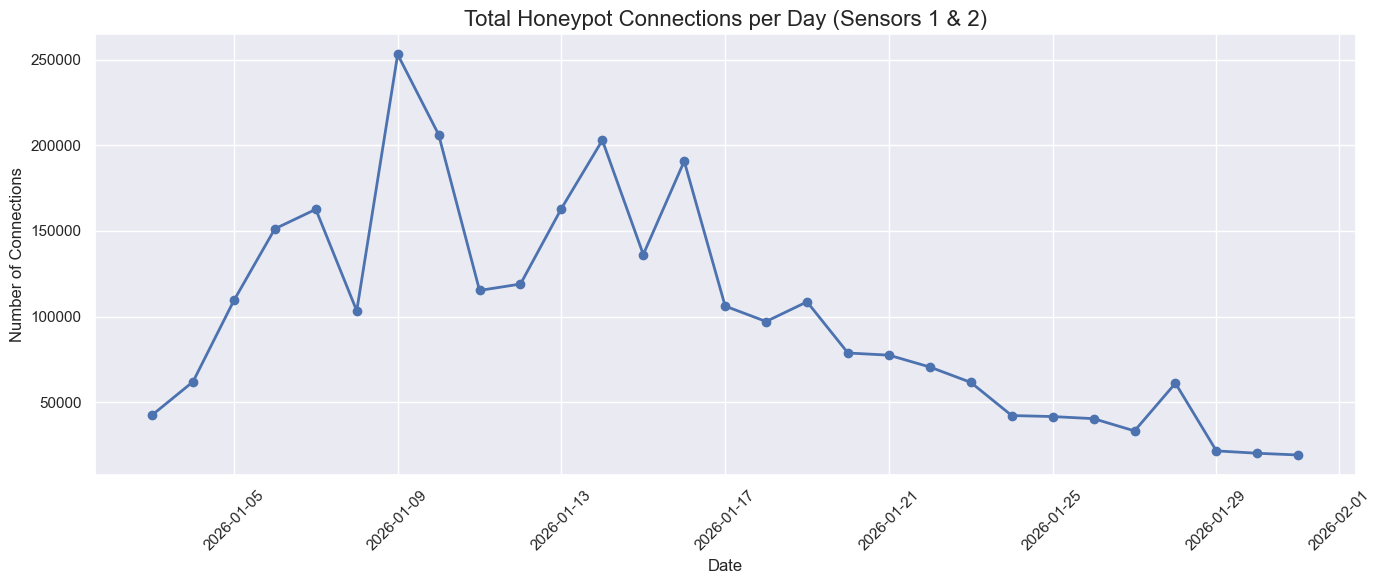

In [4]:
df_time = df_filtered.set_index('starttime') # set index
daily_attacks = df_time.resample('D').size() # sample by day

# Plot the graph
plt.figure(figsize=(14, 6))
plt.plot(daily_attacks.index, daily_attacks.values, marker='o', color='b', linewidth=2)
plt.title('Total Honeypot Connections per Day (Sensors 1 & 2)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Number of Connections', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 5. Top Attacking IP Addresses
Now we identify the specific IP addresses responsible for the highest volume of traffic. High volumes from a single IP usually indicate a dedicated brute-force script rather than a distributed botnet scan.

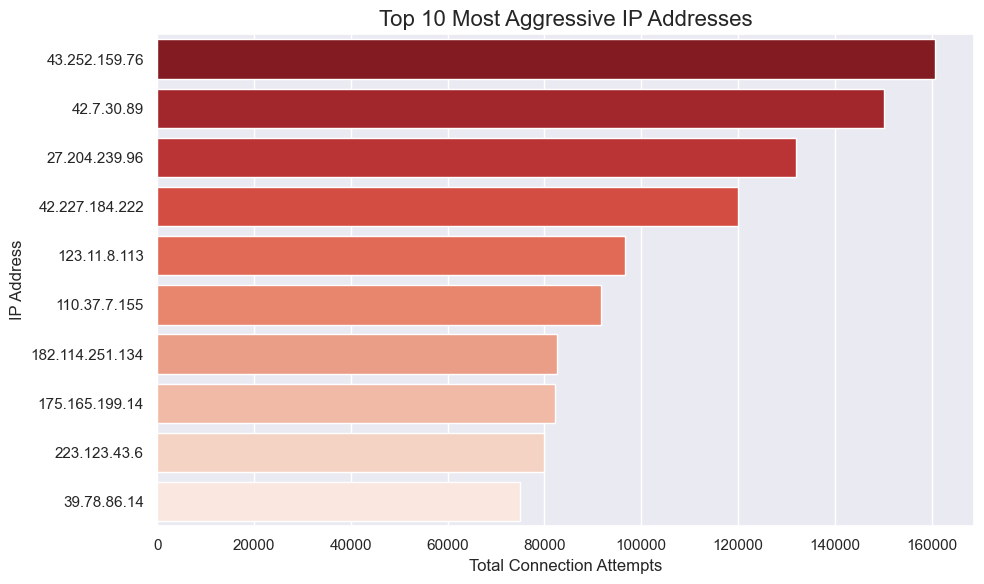

In [5]:
top_ips = df_filtered['ip'].value_counts().head(10) # count occurrences of each IP from the filtered dataset

plt.figure(figsize=(10, 6))


sns.barplot(
    x=top_ips.values,
    y=top_ips.index,
    hue=top_ips.index,
    palette='Reds_r',
    legend=False
)

plt.title('Top 10 Most Aggressive IP Addresses', fontsize=16)
plt.xlabel('Total Connection Attempts', fontsize=12)
plt.ylabel('IP Address', fontsize=12)
plt.tight_layout()
plt.show()

#### 6. Attacker Geolocation
To better understand the origin of the attacks, we will perform a geolocation lookup on the top 20 most aggressive IP addresses. We use a free IP lookup API to convert these IP addresses into their registered countries. Whilst we would like to do this with **all** IP's that connected, we are limited to the top 20 due to the rate limits of the API.

Querying IP geolocation API...


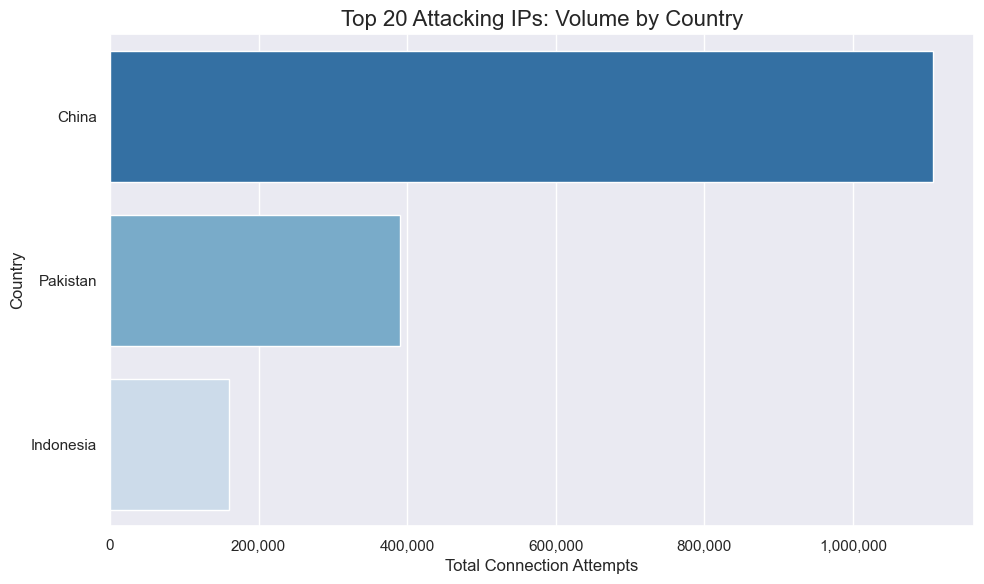

,IP,Connections,Country
0,43.252.159.76,160714,Indonesia
1,42.7.30.89,150093,China
2,27.204.239.96,132033,China
3,42.227.184.222,120055,China
4,123.11.8.113,96691,China
5,110.37.7.155,91767,Pakistan
6,182.114.251.134,82628,China
7,175.165.199.14,82228,China
8,223.123.43.6,79827,Pakistan
9,39.78.86.14,74905,China


In [6]:
import requests
import time
import matplotlib.ticker as ticker

top_20_ips = df_filtered['ip'].value_counts().head(20) # get top 20 IP's from dataset

ip_to_country = {} # dictionary to store results

print("Querying IP geolocation API...")

for ip in top_20_ips.index:
    try:
        # Query the api
        response = requests.get(f"http://ip-api.com/json/{ip}").json()

        # Extract the country ('Unknown' if it fails)
        country = response.get('country', 'Unknown')
        ip_to_country[ip] = country

        time.sleep(0.5) # sleep to avoid api rate limits
    except Exception as e:
        ip_to_country[ip] = 'Error'

# Put the data into a new dataframe
geo_df = pd.DataFrame({
    'IP': top_20_ips.index,
    'Connections': top_20_ips.values,
    'Country': [ip_to_country[ip] for ip in top_20_ips.index]
})

# Group by country
country_counts = geo_df.groupby('Country')['Connections'].sum().sort_values(ascending=False)

# Plot the results
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=country_counts.values,
    y=country_counts.index,
    hue=country_counts.index,
    palette='Blues_r',
    legend=False
)

ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}')) # turn off scientific notation

plt.title('Top 20 Attacking IPs: Volume by Country', fontsize=16)
plt.xlabel('Total Connection Attempts', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.tight_layout()
plt.show()

# Display data as table
display(geo_df.head(20))

You can see from the graph that almost all of the top 20 attackers had IP's registered in China and Pakistan. However, the single IP that attacked the honeypots the most was registered in Indonesia.

Whilst it is tempting to assume that the attackers themselves may reside in these countries due to differences in cybercrime legislation, the architecture of modern botnets suggests otherwise. Because these attacks are highly automated, these IP addresses likely belong to mass-market IoT devices that have previously been compromised by the botnet, and are now being used to try and attack the honeypots. The high volume of traffic from these regions is a reflection of the number of vulnerable internet-facing devices (such as home routers and IP cameras) that exist in these countries, rather than the physical location of the threat actors orchestrating the botnet.